# Read JADE electron data and make energy spectra

In [1]:
import datetime as dt
import numpy as np
from matplotlib import pyplot as plt

from junopy import config
from junopy import index
from junopy import jade
from junopy import utils
from junopy.constants import SID

config.ConfigVars.set_root(".junodata")   # <--- Change as necessary

Let's first define our interval and instantiate an `IndexFile` object.  Download the data. For JADE data, we also need to get the label files.

In [2]:
start = dt.datetime(2020, 1, 1, 2)
stop = dt.datetime(2020, 1, 1, 23)
jade_index = index.IndexFile(dataset='jade')
jade_files = jade_index.get_files_between_dates(start, stop, sid=SID['jade_electrons'], do_download=True, get_label=True)
jade_files

[PosixPath('/home/ysar/code/JunoPy/docs/examples/.junodata/data/jade/2020/001/JAD_L30_LRS_ELC_ANY_CNT_2020001_V04.DAT')]

In [3]:
# Let's read the first file.
jade_data_file = jade.read.JadeBinaryData(jade_files[0], start, stop)

We need to separate the data inside the file for different JADE sensors, since each sensor has a different sensitivity.

In [4]:
sensor_data = jade.sensor.SensorData(jade_data_file.data_by_packetid[106], id=106)

# The geometric factor is needed to convert from count-rate to flux or intensity.
# The JADE team uses 'def' - Differential Energy Flux [cm-2 s-1 sr-1]
#                    'dnf' - Differential Number Flux [cm-2 s-1 sr-1 keV-1]
#                    'psd' - Phase Space Densitiy [s^3 cm-6]

sensor_data.calc_geometric_factor_electrons(is_high_res=False)  # This particular file is low-res data.
sensor_data.convert_units(units_out='def')                      # units_in is `countrate` by default

# Now, we can calculate pitch angles using the onboard magnetometer.
sensor_data.calc_pitchangles()

# The data is re-binned from [LookDirection/Anode, Energy, Time] -> [PitchAngle, Energy, Time]
sensor_data.rebin_sensor_data()

# Create energy spectra by averaging over ALL pitch angles
sensor_data.calc_energy_spectra()

This will create a pandas DataFrame for the energy spectra.  The energy bins are stored in `sensor_data.energy_bins` as a 1D array.

In [5]:
sensor_data.energy_spectra.head()

,Ebin_0,Ebin_1,Ebin_2,Ebin_3,Ebin_4,Ebin_5,Ebin_6,Ebin_7,Ebin_8,Ebin_9,...,Ebin_54,Ebin_55,Ebin_56,Ebin_57,Ebin_58,Ebin_59,Ebin_60,Ebin_61,Ebin_62,Ebin_63
2020-01-01 02:06:22.132,105289.958949,46812.390521,31291.596258,31218.349167,25265.808513,16597.358026,17837.801698,15357.293740,16188.461616,14523.939729,...,5900.423712,10278.218110,10552.093234,13426.343233,8518.167845,9565.141833,20880.255357,14578.717131,17936.816349,32241.136092
2020-01-01 02:16:22.139,109530.422731,50120.463247,32628.799339,30099.961480,27348.214334,20961.191062,16037.809206,13518.840484,12728.706045,8430.210887,...,11851.504227,12735.848715,17320.914289,9093.747059,23747.856460,19271.388551,21403.097633,29573.772058,20448.564784,14444.482032
2020-01-01 02:26:22.146,86675.087178,46284.545732,35247.294895,30477.957221,22778.597727,13847.501769,15641.714701,14466.576458,12203.886529,9779.118292,...,17814.359596,13779.003656,18246.656688,14224.794340,19438.667669,22568.265125,11058.231168,11608.720344,18699.613063,20537.592506
2020-01-01 02:36:22.153,86463.510421,44449.827124,29441.652448,30863.524535,24569.417880,18810.073364,21411.115408,17056.182276,15438.405133,13741.900895,...,7834.261289,11522.135546,7745.453325,17225.813522,16294.734579,13231.739450,8054.415020,28906.552278,11497.846034,23293.711415
2020-01-01 02:46:22.160,82801.114977,48355.904456,37771.590908,23027.211950,24729.677487,20761.307046,19523.779678,12986.281102,9298.295411,11392.439188,...,8568.250064,10240.490688,6252.276289,17149.540964,7593.884806,16538.921243,17374.710229,14926.871399,19000.778876,27388.974249


## Plotting the data

Plotting is very easy using matplotlib.  Just use the `jade.plot` module. For example - 

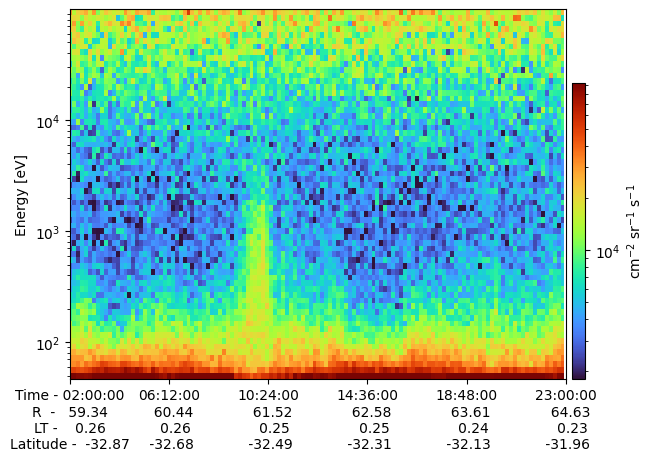

In [7]:
fig, ax = plt.subplots(1, 1)

jade.plot.plot_timeseries_spectra(
    sensor_data.energy_spectra,
    sensor_data.energy_bins,
    ax,
    cbar_label='cm$^{-2}$ sr$^{-1}$ s$^{-1}$'
)

ax.set_yscale('log')
tick_times, tick_strings = utils.plot.find_ticks_between(start, stop, nticks=6)

ax.set_xlim([tick_times[0], tick_times[-1]])
ax.xaxis.set_ticks(tick_times, tick_strings)
ax.label_outer()
ax.set_ylabel("Energy [eV]")
    
plt.show()